In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2      # OpenCV 라이브러리

from pathlib import Path
from google.colab import drive

drive.mount('/content/drive')
%cd /content/drive/MyDrive/Colab_AI 영상처리

Mounted at /content/drive
/content/drive/MyDrive/Colab_AI 영상처리


In [4]:
# 이미지 경로 읽기
Image_Path = Path('picture/sheep.jpg')
assert Image_Path.exists(), '이미지 파일 존재하지 않습니다.'

# cv2.imread() :: 이미지 읽어들이기

In [6]:
read_cv = cv2.imread(str(Image_Path))     # BGR 형식으로 읽음
if read_cv is None:
  raise FileNotFoundError('이미지를 읽지 못함')

print(read_cv.shape)    # 배열 형태 (세로(행), 가로(열), 채널수(3))
print(read_cv.dtype)    # 배열의 자료형 :: int (0 ~ 255(2^8비트))
print(read_cv.ndim)     # 배열 차원 :: 3차원

(426, 640, 3)
uint8
3


In [7]:
print(read_cv)    # BGR 형식
# 첫번째 픽셀([0][0]) :: 파랑 163, 초록 132, 빨강 107 => "조합"
# 두번째 픽셀([0][1]) :: 파랑 158, 초록 127, 빨강 102 => "조합"
# ...
# 위 규칙에 따라, 총 272,640(426*640)개의 픽셀 표현

[[[163 132 107]
  [158 127 102]
  [164 133 108]
  ...
  [111 120 129]
  [110 121 129]
  [108 119 127]]

 [[169 148 133]
  [166 145 130]
  [173 152 137]
  ...
  [106 118 130]
  [107 121 133]
  [106 120 132]]

 [[190 193 197]
  [189 192 196]
  [197 200 205]
  ...
  [126 143 164]
  [131 148 169]
  [130 147 168]]

 ...

 [[ 88 136 138]
  [ 87 136 138]
  [ 51  97 104]
  ...
  [ 69 115 122]
  [106 151 155]
  [ 85 130 134]]

 [[ 87 132 135]
  [ 60 108 110]
  [ 53  97 104]
  ...
  [ 80 126 133]
  [ 77 122 126]
  [ 92 137 141]]

 [[ 67 112 115]
  [ 59 104 107]
  [ 63 107 114]
  ...
  [ 60 106 113]
  [ 75 120 124]
  [ 83 128 132]]]


# cv2.cvtColor() :: 이미지 색상 표현방식을 변형

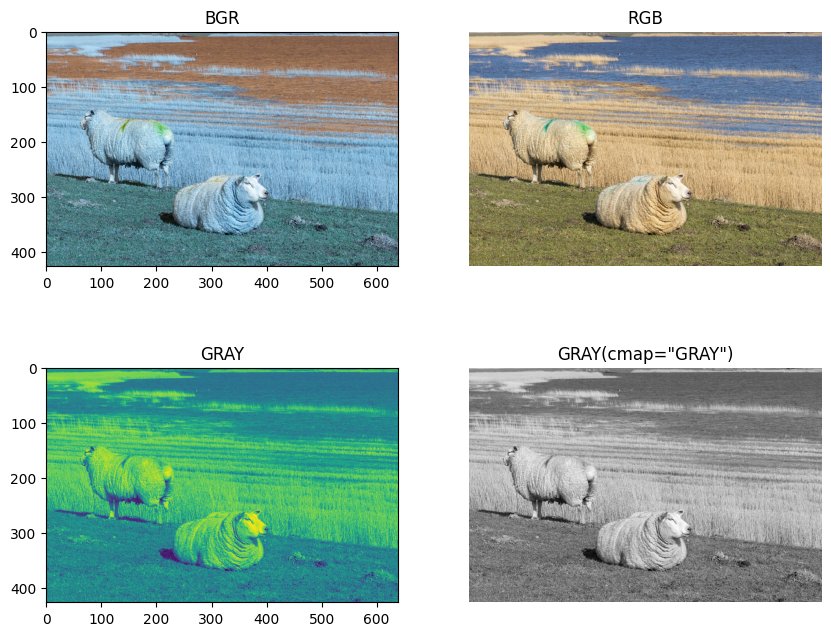

In [14]:
# 4개의 사진을 표현할 캔버스 생성
plt.figure(figsize=(10, 8))

# 첫번째 사진 (BGR 형식)
plt.subplot(2, 2, 1)
plt.imshow(read_cv)
plt.title('BGR')

# 두번째 사진 (RGB 형식)
plt.subplot(2, 2, 2)
change_rgb = cv2.cvtColor(
    read_cv,
    cv2.COLOR_BGR2RGB     # BGR to RGB
)
plt.imshow(change_rgb)    # numpy 배열값 기반 이미지 표현
plt.title('RGB')
plt.axis('off')

# 세번째 사진 (가짜 흑백)
plt.subplot(2, 2, 3)
change_gray = cv2.cvtColor(
    read_cv,
    cv2.COLOR_BGR2GRAY    # BGR to GRAY
)
plt.imshow(change_gray)
plt.title('GRAY')

# 네번째 사진 (흑백)
plt.subplot(2, 2, 4)
plt.imshow(change_gray, cmap='gray')
plt.title('GRAY(cmap="GRAY")')
plt.axis('off')

plt.show()

In [16]:
# shape값(배열 형태) 비교
print(read_cv.shape)
print(change_rgb.shape)
print(change_gray.shape)
print()
  # 흑백은 2차원 배열 (밝으면 흰색, 어두우면 검정... -> 밝기(하나의 채널)만으로 표현O)

# 특정 픽셀값 비교
print(read_cv[100][100])        # 파랑 152, 초록 156, 빨강 167
print(change_rgb[100][100])     # 빨강 167, 초록 156, 파랑 152
print(change_gray[100][100])    # 밝기 정도를 159 표현 (0(검정) ~ 255(흰색))

# plt 출력 -> RGB 형식

(426, 640, 3)
(426, 640, 3)
(426, 640)

[152 156 167]
[167 156 152]
159


# cv2.resize() :: 이미지 화질 변경 (numpy배열 크기 바꿈)

(426, 640, 3)
(100, 150, 3)


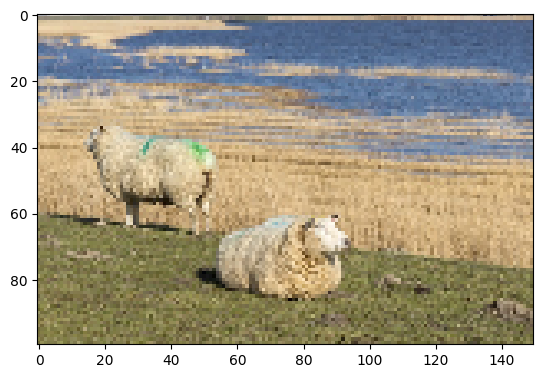

In [18]:
change_size = cv2.resize(change_rgb, (150, 100))    # (가로, 세로)

# numpy 배열 크기 비교
print(change_rgb.shape)
print(change_size.shape)

plt.imshow(change_size)
plt.show()
# 그림 표현하는 픽셀의 수가 줄어듬

# 이미지 영역 선택 (슬라이싱)

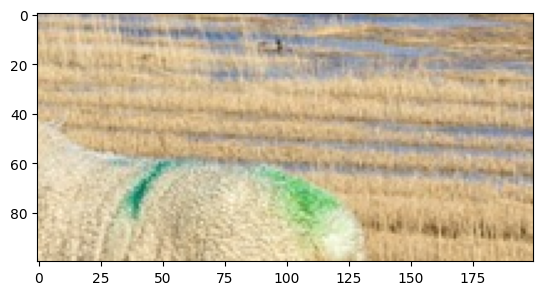

In [19]:
slicing = change_rgb[100:200, 100:300]    # [세로, 가로]
  # (100, 100) ~ (200, 300) 영역 슬라이싱

plt.imshow(slicing)
plt.show()

(426, 640, 3)


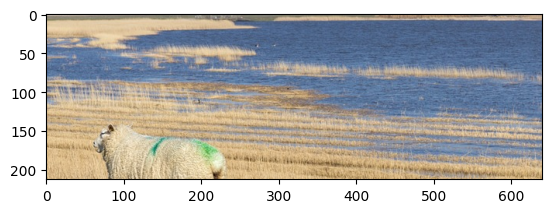

In [21]:
# 너비값, 높이값 활용 -> 슬라이싱

print(change_rgb.shape)
h, w = change_rgb.shape[:2]

slicing = change_rgb[0 : h//2, 0 : w]
plt.imshow(slicing)
plt.show()

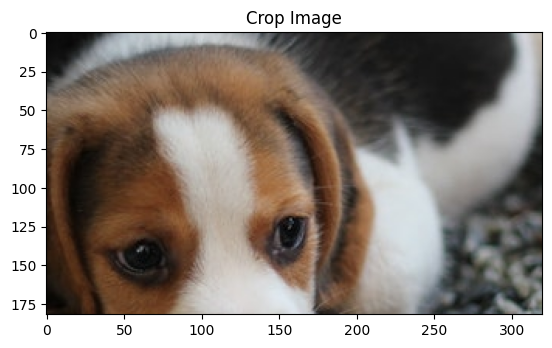

In [24]:
# 문제 정답
Image_Path = Path('picture/beagle.jpg')
assert Image_Path.exists(), "이미지 파일이 없습니다."

dog_image = cv2.imread(str(Image_Path))   # BGR 형식으로 읽음
if dog_image is None:
  raise FileNotFoundError('이미지를 읽지 못했습니다.')

dog_rgb = cv2.cvtColor(
  dog_image,
  cv2.COLOR_BGR2RGB
)

# 슬라이싱
h, w = dog_rgb.shape[:2]
crop = dog_rgb[
    h//4 : h//4*3,
    w//4 : w//4*3
] # 1/4 ~ 4/3 영역 슬라이싱

plt.imshow(crop)
plt.title('Crop Image')
plt.show()